# Thyroid levels vs. methimazole dose (prototype)

Static matplotlib prototype of the linked-panel timeline, before building it in D3.

- Data: `data/processed/personal.json`. Rerun `python scripts/prepare_personal.py` after editing the CSV.
- Dose convention: each draw's dose is what was being taken at that draw, so the change happened at the previous draw.
- Reference ranges are the UCSD lab's own, from the lab reports.
- T3 is total T3 in ng/mL (converted back from the nmol/L stored in the CSV by `prepare_personal.py`).

In [12]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

DATA = Path("..") / "data" / "processed" / "personal.json"
d = json.loads(DATA.read_text())

draws = pd.DataFrame(d["draws"])
labs = pd.DataFrame(d["labs"])
dose = pd.DataFrame(d["dose_spans"])
status = pd.DataFrame(d["status_spans"])
for df, cols in [(draws, ["date"]), (labs, ["date"]), (dose, ["start", "end"]), (status, ["start", "end"])]:
    for c in cols:
        df[c] = pd.to_datetime(df[c])

# UCSD lab reference ranges.
REF = {"TSH": (0.27, 4.20), "FT4": (0.93, 1.7), "T3": (0.8, 2.0)}
UNITS = {"TSH": "mIU/L", "FT4": "ng/dL", "T3": "total, ng/mL"}

BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#a3a29c"
STATUS_COLORS = {
    "hyperthyroid": "#e34948",
    "subclinical_hyper": "#eda100",
    "euthyroid": "#1baf7a",
    "subclinical_hypo": "#6250d6",
    "hypothyroid": "#2a78d6",
}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Every dose span after the first starts at a dose change; the last span's dose is unknown.
known = dose.dropna(subset=["dose_mg"]).reset_index(drop=True)
changes = known.iloc[1:].assign(prev_mg=known["dose_mg"].shift(1).iloc[1:])
changes[["start", "prev_mg", "dose_mg"]]

,start,prev_mg,dose_mg
1,2024-02-01,0.0,10.0
2,2024-05-20,10.0,0.0
3,2024-06-26,0.0,7.5
4,2024-08-07,7.5,5.0
5,2025-10-21,5.0,2.5
6,2026-05-29,2.5,5.0
7,2026-06-26,5.0,7.5


## 1. Timeline: dose and labs on a shared time axis

Open circles are TSH results below the detection limit (<0.01).

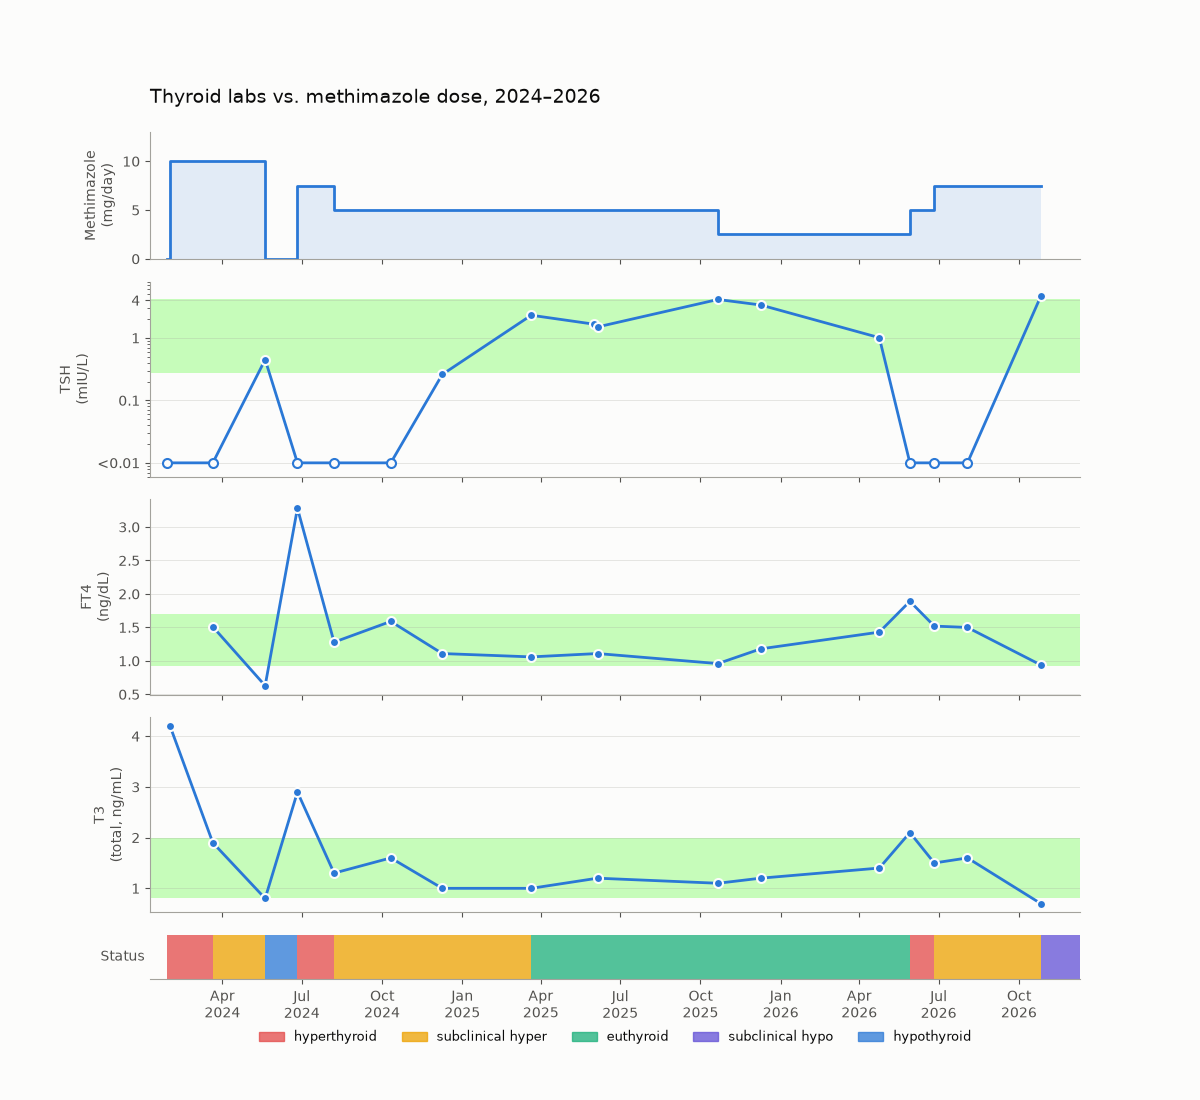

In [13]:
x_end = draws["date"].max() + pd.Timedelta(days=45)

fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 2, 2, 2, 0.45], "hspace": 0.15})
ax_dose, ax_tsh, ax_ft4, ax_t3, ax_status = axes

# Methimazole dosing changes
xs = list(known["start"]) + [known["end"].iloc[-1]]
ys = list(known["dose_mg"]) + [known["dose_mg"].iloc[-1]]
ax_dose.step(xs, ys, where="post", color=BLUE, lw=2)
ax_dose.fill_between(xs, ys, step="post", color=BLUE, alpha=0.12, lw=0)

#ax_dose.axvspan(known["end"].iloc[-1], x_end, color=MUTED, alpha=0.12, lw=0)
#ax_dose.text(known["end"].iloc[-1] + pd.Timedelta(days=4), 1, "not\nrecorded", color=INK2, fontsize=8)
#for _, c in changes.iterrows():
#    ax_dose.annotate(f"{c.prev_mg:g}→{c.dose_mg:g}", (c.start, max(c.prev_mg, c.dose_mg)),
#                     xytext=(3, 4), textcoords="offset points", fontsize=8, color=INK2)
ax_dose.set_ylim(0, 13)
ax_dose.set_ylabel("Methimazole\n(mg/day)")


def lab_panel(ax, lab, log=False):
    s = labs[labs["lab"] == lab].sort_values("date")
    if lab in REF:
        lo, hi = REF[lab]
        glow_green = "#39FF14"
        ax.axhspan(lo, hi, color=glow_green, alpha=0.05, lw=0, zorder=0)
        ax.axhspan(lo, hi, color=glow_green, alpha=0.10, lw=0, zorder=0)
        ax.axhspan(lo, hi, color=glow_green, alpha=0.15, lw=0, zorder=0)
        #ax.axhspan(lo, hi, color=MUTED, alpha=0.18, lw=0)
        #ax.text(x_end, hi, "typical range ", ha="right", va="bottom", fontsize=8, color=INK2)
    ax.plot(s["date"], s["value"], color=BLUE, lw=2, zorder=2)
    ok, cen = s[~s["censored"]], s[s["censored"]]
    ax.scatter(ok["date"], ok["value"], s=42, color=BLUE, edgecolor=SURFACE, lw=1.5, zorder=3)
    ax.scatter(cen["date"], cen["value"], s=42, facecolor=SURFACE, edgecolor=BLUE, lw=1.5, zorder=3)
    if log:
        ax.set_yscale("log")
    ax.set_ylabel(f"{lab}\n({UNITS[lab]})")
    ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)


lab_panel(ax_tsh, "TSH", log=True)
ax_tsh.set_ylim(0.006, 8)
ax_tsh.set_yticks([0.01, 0.1, 1, 4])
ax_tsh.set_yticklabels(["<0.01", "0.1", "1", "4"])
lab_panel(ax_ft4, "FT4")
lab_panel(ax_t3, "T3")

# Status strip: each draw's classification held until the next draw.
for _, s in status.iterrows():
    end = s["end"] if pd.notna(s["end"]) else x_end
    ax_status.axvspan(s["start"], end, color=STATUS_COLORS[s["status"]], alpha=0.75, lw=0)
ax_status.set_yticks([])
ax_status.spines["left"].set_visible(False)
ax_status.set_ylabel("Status", rotation=0, ha="right", va="center")
ax_status.legend(handles=[Patch(color=c, alpha=0.75, label=k.replace("_", " ")) for k, c in STATUS_COLORS.items()],
                 loc="upper center", bbox_to_anchor=(0.5, -0.9), ncol=5, frameon=False, fontsize=9)

ax_status.set_xlim(draws["date"].min() - pd.Timedelta(days=20), x_end)
ax_status.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax_status.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("Thyroid labs vs. methimazole dose, 2024–2026", x=0.125, y=0.92, ha="left", fontsize=14)
fig.savefig("timeline.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Raw vs. normalized toggle

Use the buttons to switch views (needs the live Jupyter server; static exports show only the default).

- **Raw**: each lab in its own units, with the lab's reference band.
- **Normalized**: `(value - low) / (high - low)` on a shared axis, so 0 is the bottom of the reference range and 1 is the top. TSH is normalized on a log scale.
- **Overlay**: all three labs on one panel, normalized the same way. Nothing is flipped: when Free T4 and T3 rise, TSH falls (the feedback loop), so TSH moves opposite to the other two.

Open circles are TSH results below the detection limit (<0.01).

**Hover** over any panel to drop a vertical line through all of them. It snaps to the nearest draw and shows that draw's date, dose, status and raw lab values. (This needs the interactive `ipympl` backend, enabled by `%matplotlib widget` at the top of the cell below.)

In [16]:
%matplotlib widget
import ipywidgets as widgets
import numpy as np

LAB_COLORS = {"TSH": BLUE, "FT4": ORANGE, "T3": INK2}
LAB_NAMES = {"TSH": "TSH", "FT4": "Free T4", "T3": "Total T3"}
HOVER_UNITS = {"TSH": "mIU/L", "FT4": "ng/dL", "T3": "ng/mL"}


def normalize(lab, values):
    lo, hi = REF[lab]
    v = np.asarray(values, dtype=float)
    if lab == "TSH":
        v, lo, hi = np.log10(v), np.log10(lo), np.log10(hi)
    return (v - lo) / (hi - lo)


def draw_lab(ax, s, lab, mode):
    color = LAB_COLORS[lab]
    y = s["value"] if mode == "Raw" else normalize(lab, s["value"])
    ax.plot(s["date"], y, color=color, lw=2, zorder=2)
    cen = s["censored"].to_numpy()
    ax.scatter(s["date"][~cen], np.asarray(y)[~cen], s=42, color=color, edgecolor=SURFACE, lw=1.5, zorder=3)
    ax.scatter(s["date"][cen], np.asarray(y)[cen], s=42, facecolor=SURFACE, edgecolor=color, lw=1.5, zorder=3)


def plot_timeline(mode="Raw"):
    plt.close("all")
    lab_list = ["TSH", "FT4", "T3"]
    n_lab = 1 if mode == "Overlay" else 3
    fig, axes = plt.subplots(n_lab + 2, 1, figsize=(12, 4 + 2.2 * n_lab), sharex=True,
                             gridspec_kw={"height_ratios": [1.3] + [2] * n_lab + [0.45], "hspace": 0.15})
    ax_dose, ax_status = axes[0], axes[-1]
    lab_axes = axes[1:-1]

    ax_dose.step(xs, ys, where="post", color=BLUE, lw=2)
    ax_dose.fill_between(xs, ys, step="post", color=BLUE, alpha=0.12, lw=0)
    ax_dose.set_ylim(0, 13)
    ax_dose.set_ylabel("Methimazole\n(mg/day)")

    series = {lab: labs[labs["lab"] == lab].sort_values("date").reset_index(drop=True) for lab in lab_list}
    for i, lab in enumerate(lab_list):
        ax = lab_axes[0] if mode == "Overlay" else lab_axes[i]
        draw_lab(ax, series[lab], lab, mode)

    if mode == "Raw":
        for ax, lab in zip(lab_axes, lab_list):
            lo, hi = REF[lab]
            ax.axhspan(lo, hi, color="#39FF14", alpha=0.30, lw=0, zorder=0)
            ax.set_ylabel(f"{LAB_NAMES[lab]}\n({UNITS[lab]})")
        lab_axes[0].set_yscale("log")
        lab_axes[0].set_ylim(0.006, 8)
        lab_axes[0].set_yticks([0.01, 0.1, 1, 4])
        lab_axes[0].set_yticklabels(["<0.01", "0.1", "1", "4"])
    else:
        for ax in lab_axes:
            ax.axhspan(0, 1, color="#39FF14", alpha=0.30, lw=0, zorder=0)
            ax.set_ylim(-1.5, 3.3)
            ax.set_yticks([0, 1])
            ax.set_yticklabels(["low limit", "high limit"])
        if mode == "Normalized":
            for ax, lab in zip(lab_axes, lab_list):
                ax.set_ylabel(f"{LAB_NAMES[lab]}\n(log scale)" if lab == "TSH" else LAB_NAMES[lab])
        else:
            lab_axes[0].set_ylabel("position in reference range\n(0 = low limit, 1 = high limit)")
            lab_axes[0].legend(handles=[Line2D([0], [0], color=LAB_COLORS[l], lw=2,
                                               label=LAB_NAMES[l])
                                        for l in lab_list], loc="upper left", frameon=False, ncol=3, fontsize=9)
    for ax in lab_axes:
        ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)

    for _, s in status.iterrows():
        end = s["end"] if pd.notna(s["end"]) else x_end
        ax_status.axvspan(s["start"], end, color=STATUS_COLORS[s["status"]], alpha=0.75, lw=0)
    ax_status.set_yticks([])
    ax_status.spines["left"].set_visible(False)
    ax_status.set_ylabel("Status", rotation=0, ha="right", va="center")
    ax_status.set_xlim(draws["date"].min() - pd.Timedelta(days=20), x_end)
    ax_status.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax_status.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    fig.suptitle(f"Thyroid labs vs. methimazole dose ({mode.lower()})", x=0.125, y=0.94, ha="left", fontsize=14)
    # Hover: a vertical line follows the cursor through every panel, snapped to the nearest draw.
    dnums = mdates.date2num(draws["date"])
    NL = chr(10)
    hint = "Hover over the chart to compare a draw across panels"
    vlines = [ax.axvline(dnums[0], color=INK, lw=1, alpha=0.7, zorder=4, visible=False) for ax in axes]
    info = fig.text(0.9, 0.94, hint, ha="right", va="top", fontsize=9, color=INK2)
    state = {"i": None}

    def readout(i):
        d = draws.iloc[i]
        head = f"{d['date']:%b %d, %Y}   {d['dose_mg']:g} mg/day   {d['status'].replace('_', ' ')}"
        vals = []
        for lab in lab_list:
            row = series[lab][series[lab]["draw_id"] == d["id"]]
            if row.empty:
                vals.append(f"{LAB_NAMES[lab]} -")
                continue
            r = row.iloc[0]
            txt = "<0.01" if r["censored"] else f"{r['value']:g}"
            vals.append(f"{LAB_NAMES[lab]} {txt} {HOVER_UNITS[lab]}")
        return head + NL + "   ".join(vals)

    def on_move(event):
        if event.inaxes is None or event.xdata is None:
            return on_leave(event)
        i = int(np.argmin(np.abs(dnums - event.xdata)))
        if i == state["i"]:
            return
        state["i"] = i
        for v in vlines:
            v.set_xdata([dnums[i], dnums[i]])
            v.set_visible(True)
        info.set_text(readout(i))
        fig.canvas.draw_idle()

    def on_leave(event):
        if state["i"] is None:
            return
        state["i"] = None
        for v in vlines:
            v.set_visible(False)
        info.set_text(hint)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("motion_notify_event", on_move)
    fig.canvas.mpl_connect("figure_leave_event", on_leave)
    plt.show()


from matplotlib.lines import Line2D

toggle = widgets.ToggleButtons(options=["Raw", "Normalized", "Overlay"], value="Raw", description="View:")
out = widgets.interactive_output(plot_timeline, {"mode": toggle})
display(toggle, out)

ToggleButtons(description='View:', options=('Raw', 'Normalized', 'Overlay'), value='Raw')

Output()

## 3. All other biomarkers

Same views as section 2, but for every non-thyroid lab in the record (metabolic panel, blood counts, liver, lipids, and so on). The methimazole dose stays on top so you can see what you were taking at each draw.

- Data: `data/processed/all_labs.csv`. Rebuild it with `python scripts/extract_all_labs.py <export folder> data/processed/all_labs.csv`.
- Pick a **group**, then pick up to 8 **tests** (Ctrl/Cmd-click for several). Only tests with at least two results are listed.
- **Normalized** uses each result's own reference range: `(value - low) / (high - low)`. Tests with only an upper limit (for example bilirubin below 1.2) are measured from zero. Tests with no range are skipped in this view.
- Open circles are results the lab reported as a limit (for example eGFR above 60).
- **Hover** drops a line through every panel, snapped to the nearest draw, and lists that day's values in the side panel.
- Most of these tests were drawn only 6 or 7 times between 2017 and 2025, so the lines are sparse.

In [18]:
from pathlib import Path

bio = pd.read_csv(Path("..") / "data" / "processed" / "all_labs.csv", parse_dates=["date"])
bio = bio[bio["group"] != "Thyroid"].copy()
bio["unit"] = bio["unit"].fillna("")
bio["censored"] = bio["censor"].notna()
bio["hi"] = bio["ref_high"]
# A test with only an upper limit is measured from zero.
bio["lo"] = bio["ref_low"].where(bio["ref_low"].notna(), np.where(bio["ref_high"].notna(), 0.0, np.nan))
bio["norm"] = (bio["value"] - bio["lo"]) / (bio["hi"] - bio["lo"])

n_results = bio.groupby("test")["date"].nunique()
GROUP_TESTS = {g: sorted(d["test"].unique()) for g, d in bio[bio["test"].map(n_results) >= 2].groupby("group")}
BIO_COLORS = [BLUE, ORANGE, "#1baf7a", "#6250d6", "#e34948", "#eda100", INK2, "#1fa5b8"]
MAX_TESTS = 8


def dose_on(day):
    for _, r in dose.iterrows():
        if r["start"] <= day and (pd.isna(r["end"]) or day < r["end"] or r["start"] == r["end"] == day):
            return None if pd.isna(r["dose_mg"]) else r["dose_mg"]
    return None


def plot_bio(mode="Raw", tests=()):
    plt.close("all")
    tests = list(tests)[:MAX_TESTS]
    if not tests:
        print("Pick at least one test.")
        return
    data = {t: bio[bio["test"] == t].sort_values("date") for t in tests}
    shown = tests if mode == "Raw" else [t for t in tests if data[t]["norm"].notna().any()]
    if len(shown) < len(tests):
        print("No reference range, skipped in this view: " + ", ".join(t for t in tests if t not in shown))
    if not shown:
        return

    n_lab = 1 if mode == "Overlay" else len(shown)
    fig, axes = plt.subplots(n_lab + 1, 1, figsize=(12, 2.6 + 2.1 * n_lab), sharex=True,
                             gridspec_kw={"height_ratios": [1.1] + [2] * n_lab, "hspace": 0.25})
    fig.subplots_adjust(left=0.1, right=0.74)
    ax_dose, lab_axes = axes[0], axes[1:]

    ax_dose.step(xs, ys, where="post", color=BLUE, lw=2)
    ax_dose.fill_between(xs, ys, step="post", color=BLUE, alpha=0.12, lw=0)
    ax_dose.set_ylim(0, 13)
    ax_dose.set_ylabel("Methimazole\n(mg/day)")

    all_y = {}
    for i, t in enumerate(shown):
        s = data[t]
        ax = lab_axes[0] if mode == "Overlay" else lab_axes[i]
        color = BIO_COLORS[i % len(BIO_COLORS)]
        y = s["value"] if mode == "Raw" else s["norm"]
        ok = y.notna()
        cen = s["censored"] & ok
        ax.plot(s["date"][ok], y[ok], color=color, lw=2, zorder=2, label=t)
        ax.scatter(s["date"][ok & ~cen], y[ok & ~cen], s=42, color=color, edgecolor=SURFACE, lw=1.5, zorder=3)
        ax.scatter(s["date"][cen], y[cen], s=42, facecolor=SURFACE, edgecolor=color, lw=1.5, zorder=3)
        all_y[t] = y[ok]

        if mode == "Raw":
            latest = s[s["hi"].notna()].tail(1)
            lo_v, hi_v = y.min(), y.max()
            if not latest.empty:
                r = latest.iloc[0]
                ax.axhspan(r["lo"], r["hi"], color="#39FF14", alpha=0.30, lw=0, zorder=0)
                lo_v, hi_v = min(lo_v, r["lo"]), max(hi_v, r["hi"])
            pad = (hi_v - lo_v) * 0.12 or 1
            ax.set_ylim(lo_v - pad, hi_v + pad)
            unit = s["unit"].iloc[0]
            ax.set_ylabel(f"{t}\n({unit})" if unit else t, fontsize=9)
            ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)

    if mode != "Raw":
        stack = pd.concat(all_y.values())
        lo_v, hi_v = min(-0.3, stack.min()), max(1.3, stack.max())
        pad = (hi_v - lo_v) * 0.08
        for ax in lab_axes:
            ax.axhspan(0, 1, color="#39FF14", alpha=0.30, lw=0, zorder=0)
            ax.set_ylim(lo_v - pad, hi_v + pad)
            ax.set_yticks([0, 1])
            ax.set_yticklabels(["low limit", "high limit"])
            ax.grid(axis="y", color=MUTED, alpha=0.3, lw=0.6)
        if mode == "Normalized":
            for ax, t in zip(lab_axes, shown):
                ax.set_ylabel(t, fontsize=9)
        else:
            lab_axes[0].set_ylabel("position in reference range\n(0 = low limit, 1 = high limit)")
            lab_axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)

    dates = pd.concat([data[t]["date"] for t in shown])
    ax_dose.set_xlim(dates.min() - pd.Timedelta(days=90), x_end)
    lab_axes[-1].xaxis.set_major_locator(mdates.YearLocator())
    lab_axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.suptitle(f"Other biomarkers vs. methimazole dose ({mode.lower()})", x=0.1, y=0.98, ha="left", fontsize=14)

    # Hover: a vertical line through every panel, snapped to the nearest draw.
    snap = mdates.date2num(sorted(dates.unique()))
    hint = "Hover over the chart\nto compare a draw\nacross panels"
    vlines = [ax.axvline(snap[0], color=INK, lw=1, alpha=0.7, zorder=4, visible=False) for ax in axes]
    info = fig.text(0.76, 0.93, hint, ha="left", va="top", fontsize=9, color=INK2)
    state = {"i": None}

    def readout(i):
        day = pd.Timestamp(mdates.num2date(snap[i]).date())
        mg = dose_on(day)
        lines = [f"{day:%b %d, %Y}", "methimazole: " + ("n/a" if mg is None else f"{mg:g} mg/day"), ""]
        for t in shown:
            row = data[t][data[t]["date"] == day]
            if row.empty:
                continue
            r = row.iloc[0]
            flag = " (high)" if pd.notna(r["hi"]) and r["value"] > r["hi"] else \
                   " (low)" if pd.notna(r["lo"]) and r["value"] < r["lo"] else ""
            lines.append(f"{t}: {r['censor'] if pd.notna(r['censor']) else ''}{r['value']:g} {r['unit']}{flag}")
        return "\n".join(lines)

    def on_move(event):
        if event.inaxes is None or event.xdata is None:
            return on_leave(event)
        i = int(np.argmin(np.abs(snap - event.xdata)))
        if i == state["i"]:
            return
        state["i"] = i
        for v in vlines:
            v.set_xdata([snap[i], snap[i]])
            v.set_visible(True)
        info.set_text(readout(i))
        fig.canvas.draw_idle()

    def on_leave(event):
        if state["i"] is None:
            return
        state["i"] = None
        for v in vlines:
            v.set_visible(False)
        info.set_text(hint)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("motion_notify_event", on_move)
    fig.canvas.mpl_connect("figure_leave_event", on_leave)
    plt.show()


bio_group = widgets.Dropdown(options=list(GROUP_TESTS), value="Liver", description="Group:")
bio_tests = widgets.SelectMultiple(options=GROUP_TESTS["Liver"], value=tuple(GROUP_TESTS["Liver"][:3]),
                                   rows=8, description="Tests:", layout=widgets.Layout(width="360px"))


def on_group(change):
    bio_tests.options = GROUP_TESTS[change["new"]]
    bio_tests.value = tuple(GROUP_TESTS[change["new"]][:3])


bio_group.observe(on_group, names="value")
bio_toggle = widgets.ToggleButtons(options=["Raw", "Normalized", "Overlay"], value="Raw", description="View:")
bio_out = widgets.interactive_output(plot_bio, {"mode": bio_toggle, "tests": bio_tests})
display(widgets.VBox([bio_toggle, widgets.HBox([bio_group, bio_tests])]), bio_out)

Output()